In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [2]:
df=pd.read_csv('/kaggle/input/dataco-smart-supply-chain-for-big-data-analysis/DataCoSupplyChainDataset.csv',encoding='latin1')

In [3]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [4]:
df.shape

(180519, 53)

In [5]:
df.isnull().sum()

Type                                  0
Days for shipping (real)              0
Days for shipment (scheduled)         0
Benefit per order                     0
Sales per customer                    0
Delivery Status                       0
Late_delivery_risk                    0
Category Id                           0
Category Name                         0
Customer City                         0
Customer Country                      0
Customer Email                        0
Customer Fname                        0
Customer Id                           0
Customer Lname                        8
Customer Password                     0
Customer Segment                      0
Customer State                        0
Customer Street                       0
Customer Zipcode                      3
Department Id                         0
Department Name                       0
Latitude                              0
Longitude                             0
Market                                0


In [6]:
df['Customer Full Name'] = df['Customer Fname']+df['Customer Lname']

In [7]:
df['Customer Full Name']

0            CallyHolloway
1                IreneLuna
2         GillianMaldonado
3                 TanaTate
4            OrliHendricks
                ...       
180514       MariaPeterson
180515         RonaldClark
180516           JohnSmith
180517           MarySmith
180518        AndreaOrtega
Name: Customer Full Name, Length: 180519, dtype: object

In [8]:
df.shape

(180519, 54)

In [9]:
san=df.drop(['Customer Email','Product Status','Customer Password','Customer Street','Customer Fname','Customer Lname',
           'Latitude','Longitude','Product Description','Product Image','Order Zipcode','shipping date (DateOrders)'],axis=1)
print(san)

            Type  Days for shipping (real)  Days for shipment (scheduled)  \
0          DEBIT                         3                              4   
1       TRANSFER                         5                              4   
2           CASH                         4                              4   
3          DEBIT                         3                              4   
4        PAYMENT                         2                              4   
...          ...                       ...                            ...   
180514      CASH                         4                              4   
180515     DEBIT                         3                              2   
180516  TRANSFER                         5                              4   
180517   PAYMENT                         3                              4   
180518   PAYMENT                         4                              4   

        Benefit per order  Sales per customer   Delivery Status  \
0       

In [10]:
san.shape

(180519, 42)

In [11]:
san['Customer Zipcode']=san['Customer Zipcode'].fillna(0)

/tmp/ipykernel_20/411442944.py:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  sns.heatmap(san.corr(),annot=True,linewidths=.5)


<Axes: >

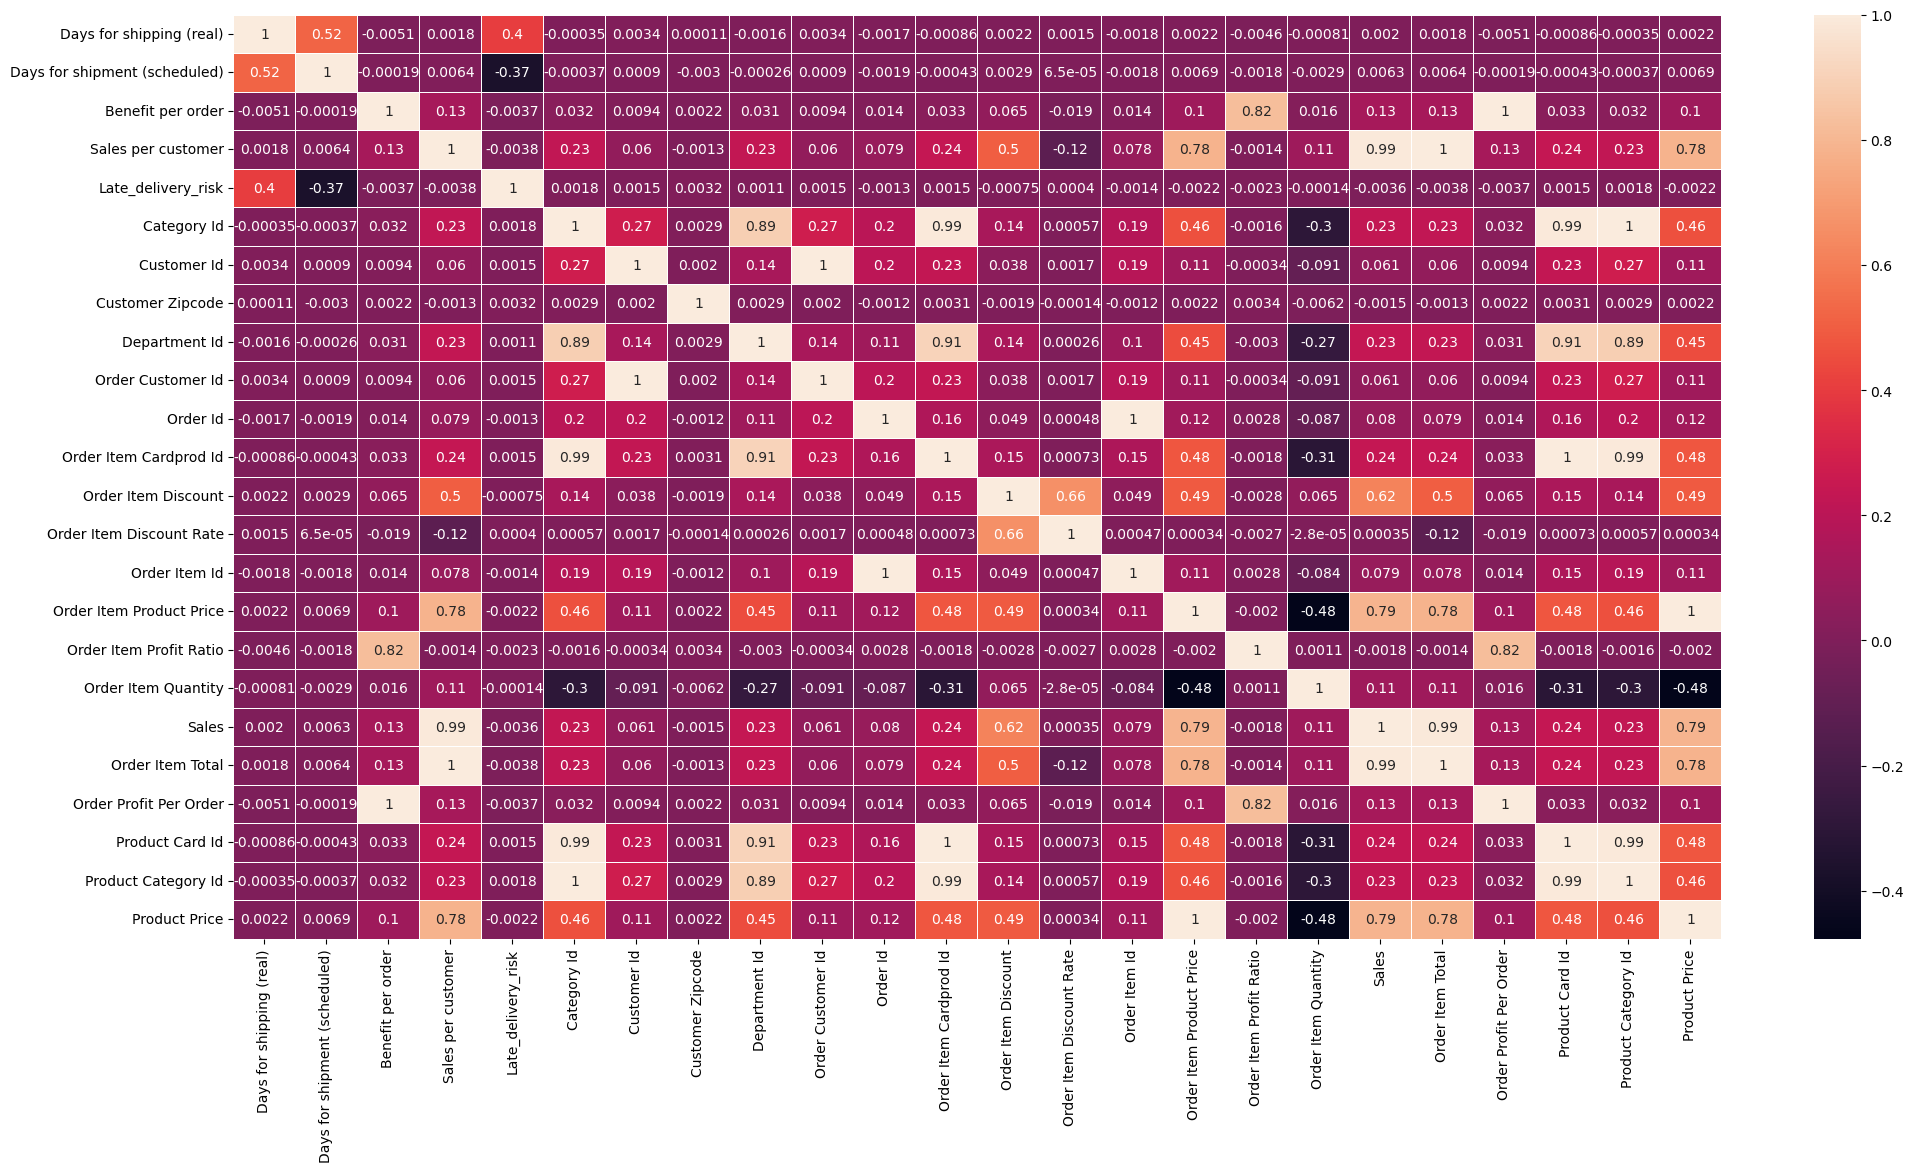

In [12]:
fig, ax = plt.subplots(figsize=(24,12))         
sns.heatmap(san.corr(),annot=True,linewidths=.5)

In [13]:
san['Type'].value_counts()

DEBIT       69295
TRANSFER    49883
PAYMENT     41725
CASH        19616
Name: Type, dtype: int64

In [14]:
san['Order Status'].value_counts()

COMPLETE           59491
PENDING_PAYMENT    39832
PROCESSING         21902
PENDING            20227
CLOSED             19616
ON_HOLD             9804
SUSPECTED_FRAUD     4062
CANCELED            3692
PAYMENT_REVIEW      1893
Name: Order Status, dtype: int64

In [15]:
san.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Id', 'Customer Segment', 'Customer State',
       'Customer Zipcode', 'Department Id', 'Department Name', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Product Card Id', 'Product Category Id', 'Product Name',
       'Product Price', 'Shipping Mode', 'Customer Full Name'],
      dtype='object')

In [16]:
san['Market'].value_counts()

LATAM           51594
Europe          50252
Pacific Asia    41260
USCA            25799
Africa          11614
Name: Market, dtype: int64

In [17]:
san['Customer Segment'].value_counts()

Consumer       93504
Corporate      54789
Home Office    32226
Name: Customer Segment, dtype: int64

In [18]:
custseg_gr=san.groupby('Order Status')

In [19]:
pd.set_option('display.max_columns',None)

### encoding techniques

In [20]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()

In [21]:
from sklearn.preprocessing import OneHotEncoder
oe=OneHotEncoder()

In [22]:
san.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 42 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Id                    180519 non-null  int64  
 12  Customer Segment              

In [23]:
len(san['Product Name'].value_counts().index)

118

In [24]:
len(san['Customer Full Name'].value_counts().index)

14025

In [25]:
len(san['Product Category Id'].value_counts().index)

51

In [26]:
len(san['Order Profit Per Order'].value_counts().index)

21998

In [27]:
san['Order Profit Per Order'].value_counts()

 0.000000      1177
 143.990005     199
 72.000000      194
 46.799999      188
 24.000000      181
               ... 
-48.830002        1
 48.220001        1
-145.729996       1
-330.109985       1
-337.100006       1
Name: Order Profit Per Order, Length: 21998, dtype: int64

In [28]:
list(san['Order Profit Per Order'].value_counts().index)

[0.0,
 143.9900055,
 72.0,
 46.79999924,
 24.0,
 18.0,
 63.70000076,
 62.40000153,
 12.0,
 14.39999962,
 22.5,
 96.0,
 30.0,
 38.22000122,
 107.9899979,
 43.68000031,
 26.39999962,
 25.20000076,
 18.89999962,
 15.0,
 11.25,
 27.29999924,
 29.39999962,
 13.5,
 43.5,
 48.0,
 94.08000183,
 13.19999981,
 58.79999924,
 19.20000076,
 42.0,
 19.79999924,
 12.60000038,
 63.0,
 36.0,
 27.0,
 86.40000153,
 49.13999939,
 9.0,
 36.40000153,
 28.79999924,
 29.10000038,
 40.95000076,
 14.69999981,
 14.25,
 45.0,
 29.70000076,
 56.77999878,
 50.95999908,
 21.60000038,
 52.40999985,
 20.0,
 90.0,
 83.98999786,
 132.2899933,
 9.600000381,
 57.40000153,
 26.10000038,
 54.59999847,
 58.5,
 87.36000061,
 39.0,
 54.0,
 28.35000038,
 52.0,
 127.3899994,
 67.19999695,
 67.5,
 10.92000008,
 31.94000053,
 31.67000008,
 45.5,
 47.25,
 14.17000008,
 36.02999878,
 56.0,
 98.0,
 53.75999832,
 49.91999817,
 10.80000019,
 52.91999817,
 43.20000076,
 12.30000019,
 40.5,
 41.40000153,
 88.19000244,
 117.5899963,
 115.

In [29]:
san[['Type','Order Profit Per Order']].head(40)

,Type,Order Profit Per Order
0,DEBIT,91.250000
1,TRANSFER,-249.089996
2,CASH,-247.779999
3,DEBIT,22.860001
4,PAYMENT,134.210007
5,TRANSFER,18.580000
6,DEBIT,95.180000
7,TRANSFER,68.430000
8,CASH,133.720001
9,CASH,132.149994


In [30]:
san.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 42 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Id                    180519 non-null  int64  
 12  Customer Segment              

In [31]:
obj_num=['Type','Category Name','Customer City','Customer Country','Customer Segment','Customer State',
         'Department Name','Market','Order City','Order Country','Order Region','Order State'
        'Order State','Product Name','Shipping Mode','Customer Full Name']

In [32]:
san['Delivery Status'].value_counts()

Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: Delivery Status, dtype: int64

In [33]:
san[(san['Delivery Status']=='Late delivery')&(san['Late_delivery_risk']==0)]

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Id,Customer Segment,Customer State,Customer Zipcode,Department Id,Department Name,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Card Id,Product Category Id,Product Name,Product Price,Shipping Mode,Customer Full Name


In [34]:
san[(san['Delivery Status']=='Late delivery')&(san['Late_delivery_risk']==1)]

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Id,Customer Segment,Customer State,Customer Zipcode,Department Id,Department Name,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Card Id,Product Category Id,Product Name,Product Price,Shipping Mode,Customer Full Name
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,19492,Consumer,PR,725.0,2,Fitness,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.750000,-0.80,1,327.750000,311.359985,-249.089996,South Asia,Rajastán,PENDING,1360,73,Smart watch,327.750000,Standard Class,IreneLuna
6,DEBIT,2,1,95.180000,288.420013,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,19487,Home Office,PR,725.0,2,Fitness,Pacific Asia,Guangzhou,China,19487,1/13/2018 10:42,75934,1360,39.330002,0.12,179249,327.750000,0.33,1,327.750000,288.420013,95.180000,Eastern Asia,Guangdong,COMPLETE,1360,73,Smart watch,327.750000,First Class,ConstanceTerrell
7,TRANSFER,2,1,68.430000,285.140015,Late delivery,1,73,Sporting Goods,Miami,EE. UU.,19486,Corporate,FL,33162.0,2,Fitness,Pacific Asia,Guangzhou,China,19486,1/13/2018 10:21,75933,1360,42.610001,0.13,179248,327.750000,0.24,1,327.750000,285.140015,68.430000,Eastern Asia,Guangdong,PROCESSING,1360,73,Smart watch,327.750000,First Class,EricaStevens
8,CASH,3,2,133.720001,278.589996,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,19485,Corporate,PR,725.0,2,Fitness,Pacific Asia,Guangzhou,China,19485,1/13/2018 10:00,75932,1360,49.160000,0.15,179247,327.750000,0.48,1,327.750000,278.589996,133.720001,Eastern Asia,Guangdong,CLOSED,1360,73,Smart watch,327.750000,Second Class,NicholeOlsen
9,CASH,2,1,132.149994,275.309998,Late delivery,1,73,Sporting Goods,San Ramon,EE. UU.,19484,Corporate,CA,94583.0,2,Fitness,Pacific Asia,Guangzhou,China,19484,1/13/2018 9:39,75931,1360,52.439999,0.16,179246,327.750000,0.48,1,327.750000,275.309998,132.149994,Eastern Asia,Guangdong,CLOSED,1360,73,Smart watch,327.750000,First Class,OprahDelacruz
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180507,PAYMENT,5,2,50.110001,347.980011,Late delivery,1,45,Fishing,Philadelphia,EE. UU.,8247,Consumer,PA,19134.0,7,Fan Shop,Pacific Asia,Hanoi,Vietnam,8247,1/16/2016 9:16,26059,1004,52.000000,0.13,65219,399.980011,0.14,1,399.980011,347.980011,50.110001,Southeast Asia,Th? Dô Hà N?i,PAYMENT_REVIEW,1004,45,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,Second Class,MarySmith
180508,DEBIT,4,2,85.000000,339.980011,Late delivery,1,45,Fishing,Waipahu,EE. UU.,8387,Corporate,HI,96797.0,7,Fan Shop,Pacific Asia,Guangshui,China,8387,1/16/2016 7:10,26053,1004,60.000000,0.15,65206,399.980011,0.25,1,399.980011,339.980011,85.000000,Eastern Asia,Hubei,COMPLETE,1004,45,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,Second Class,RichardFuentes
180512,DEBIT,6,4,86.400002,319.980011,Late delivery,1,45,Fishing,Caguas,Puerto Rico,7396,Home Office,PR,725.0,7,Fan Shop,Pacific Asia,Chengdu,China,7396,1/16/2016 6:07,26050,1004,80.000000,0.20,65194,399.980011,0.27,1,399.980011,319.980011,86.400002,Eastern Asia,Sichuan,COMPLETE,1004,45,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,Standard Class,MaryMadden
180515,DEBIT,3,2,-613.770019,395.980011,Late delivery,1,45,Fishing,Bakersfield,EE. UU.,9141,Corporate,CA,93304.0,7,Fan Shop,Pacific Asia,Hirakata,Japón,9141,1/16/2016 1:34,26037,1004,4.000000,0.01,65161,399.980011,-1.55,1,399.980011,395.980011,-613.770019,Eastern Asia,Osaka,COMPLETE,1004,45,Fie

In [35]:
san[san['Late_delivery_risk']==1]

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Id,Customer Segment,Customer State,Customer Zipcode,Department Id,Department Name,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Card Id,Product Category Id,Product Name,Product Price,Shipping Mode,Customer Full Name
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,19492,Consumer,PR,725.0,2,Fitness,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.750000,-0.80,1,327.750000,311.359985,-249.089996,South Asia,Rajastán,PENDING,1360,73,Smart watch,327.750000,Standard Class,IreneLuna
6,DEBIT,2,1,95.180000,288.420013,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,19487,Home Office,PR,725.0,2,Fitness,Pacific Asia,Guangzhou,China,19487,1/13/2018 10:42,75934,1360,39.330002,0.12,179249,327.750000,0.33,1,327.750000,288.420013,95.180000,Eastern Asia,Guangdong,COMPLETE,1360,73,Smart watch,327.750000,First Class,ConstanceTerrell
7,TRANSFER,2,1,68.430000,285.140015,Late delivery,1,73,Sporting Goods,Miami,EE. UU.,19486,Corporate,FL,33162.0,2,Fitness,Pacific Asia,Guangzhou,China,19486,1/13/2018 10:21,75933,1360,42.610001,0.13,179248,327.750000,0.24,1,327.750000,285.140015,68.430000,Eastern Asia,Guangdong,PROCESSING,1360,73,Smart watch,327.750000,First Class,EricaStevens
8,CASH,3,2,133.720001,278.589996,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,19485,Corporate,PR,725.0,2,Fitness,Pacific Asia,Guangzhou,China,19485,1/13/2018 10:00,75932,1360,49.160000,0.15,179247,327.750000,0.48,1,327.750000,278.589996,133.720001,Eastern Asia,Guangdong,CLOSED,1360,73,Smart watch,327.750000,Second Class,NicholeOlsen
9,CASH,2,1,132.149994,275.309998,Late delivery,1,73,Sporting Goods,San Ramon,EE. UU.,19484,Corporate,CA,94583.0,2,Fitness,Pacific Asia,Guangzhou,China,19484,1/13/2018 9:39,75931,1360,52.439999,0.16,179246,327.750000,0.48,1,327.750000,275.309998,132.149994,Eastern Asia,Guangdong,CLOSED,1360,73,Smart watch,327.750000,First Class,OprahDelacruz
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180507,PAYMENT,5,2,50.110001,347.980011,Late delivery,1,45,Fishing,Philadelphia,EE. UU.,8247,Consumer,PA,19134.0,7,Fan Shop,Pacific Asia,Hanoi,Vietnam,8247,1/16/2016 9:16,26059,1004,52.000000,0.13,65219,399.980011,0.14,1,399.980011,347.980011,50.110001,Southeast Asia,Th? Dô Hà N?i,PAYMENT_REVIEW,1004,45,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,Second Class,MarySmith
180508,DEBIT,4,2,85.000000,339.980011,Late delivery,1,45,Fishing,Waipahu,EE. UU.,8387,Corporate,HI,96797.0,7,Fan Shop,Pacific Asia,Guangshui,China,8387,1/16/2016 7:10,26053,1004,60.000000,0.15,65206,399.980011,0.25,1,399.980011,339.980011,85.000000,Eastern Asia,Hubei,COMPLETE,1004,45,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,Second Class,RichardFuentes
180512,DEBIT,6,4,86.400002,319.980011,Late delivery,1,45,Fishing,Caguas,Puerto Rico,7396,Home Office,PR,725.0,7,Fan Shop,Pacific Asia,Chengdu,China,7396,1/16/2016 6:07,26050,1004,80.000000,0.20,65194,399.980011,0.27,1,399.980011,319.980011,86.400002,Eastern Asia,Sichuan,COMPLETE,1004,45,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,Standard Class,MaryMadden
180515,DEBIT,3,2,-613.770019,395.980011,Late delivery,1,45,Fishing,Bakersfield,EE. UU.,9141,Corporate,CA,93304.0,7,Fan Shop,Pacific Asia,Hirakata,Japón,9141,1/16/2016 1:34,26037,1004,4.000000,0.01,65161,399.980011,-1.55,1,399.980011,395.980011,-613.770019,Eastern Asia,Osaka,COMPLETE,1004,45,Fie

In [36]:
san[san['Order Status']=='SUSPECTED_FRAUD']

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Id,Customer Segment,Customer State,Customer Zipcode,Department Id,Department Name,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Card Id,Product Category Id,Product Name,Product Price,Shipping Mode,Customer Full Name
10,TRANSFER,6,2,130.580002,272.029999,Shipping canceled,0,73,Sporting Goods,Caguas,Puerto Rico,19483,Corporate,PR,725.0,2,Fitness,Pacific Asia,Tokio,Japón,19483,1/13/2018 9:18,75930,1360,55.720001,0.17,179245,327.750000,0.48,1,327.750000,272.029999,130.580002,Eastern Asia,Tokio,SUSPECTED_FRAUD,1360,73,Smart watch,327.750000,Second Class,GermaneShort
24,TRANSFER,2,2,90.279999,288.420013,Shipping canceled,0,73,Sporting Goods,Billings,EE. UU.,19469,Corporate,MT,59102.0,2,Fitness,Pacific Asia,Brisbane,Australia,19469,1/13/2018 4:24,75916,1360,39.330002,0.12,179231,327.750000,0.31,1,327.750000,288.420013,90.279999,Oceania,Queensland,SUSPECTED_FRAUD,1360,73,Smart watch,327.750000,Second Class,SimoneVance
183,TRANSFER,5,4,28.850000,128.220001,Shipping canceled,0,13,Electronics,Freeport,EE. UU.,1509,Consumer,NY,11520.0,3,Footwear,USCA,Houston,Estados Unidos,1509,5/8/2016 17:42,33824,278,6.750000,0.05,84424,44.990002,0.23,3,134.970001,128.220001,28.850000,US Center,Texas,SUSPECTED_FRAUD,278,13,Under Armour Men's Compression EV SL Slide,44.990002,Standard Class,PatriciaPetersen
184,TRANSFER,5,4,133.910004,278.970001,Shipping canceled,0,9,Cardio Equipment,Fort Washington,EE. UU.,1636,Consumer,MD,20744.0,3,Footwear,USCA,Gilbert,Estados Unidos,1636,4/2/2016 19:51,31364,191,21.000000,0.07,78398,99.989998,0.48,3,299.970001,278.970001,133.910004,West of USA,Arizona,SUSPECTED_FRAUD,191,9,Nike Men's Free 5.0+ Running Shoe,99.989998,Standard Class,JuliePetersen
185,TRANSFER,6,4,79.160004,272.970001,Shipping canceled,0,9,Cardio Equipment,Bakersfield,EE. UU.,2784,Consumer,CA,93304.0,3,Footwear,USCA,San Jose,Estados Unidos,2784,8/14/2016 2:51,40495,191,27.000000,0.09,101052,99.989998,0.29,3,299.970001,272.970001,79.160004,West of USA,California,SUSPECTED_FRAUD,191,9,Nike Men's Free 5.0+ Running Shoe,99.989998,Standard Class,LisaSmith
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180274,TRANSFER,5,2,163.190002,339.980011,Shipping canceled,0,45,Fishing,Caguas,Puerto Rico,3830,Corporate,PR,725.0,7,Fan Shop,Pacific Asia,Matsubara,Japón,3830,1/29/2016 3:49,26934,1004,60.000000,0.15,67470,399.980011,0.48,1,399.980011,339.980011,163.190002,Eastern Asia,Oita,SUSPECTED_FRAUD,1004,45,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,Second Class,WilliamSmith
180309,TRANSFER,2,1,114.830002,347.980011,Shipping canceled,0,45,Fishing,Modesto,EE. UU.,467,Consumer,CA,95350.0,7,Fan Shop,Pacific Asia,Shenyang,China,467,1/26/2016 21:52,26780,1004,52.000000,0.13,67096,399.980011,0.33,1,399.980011,347.980011,114.830002,Eastern Asia,Liaoning,SUSPECTED_FRAUD,1004,45,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,First Class,JamesSmith
180352,TRANSFER,4,4,90.000000,399.980011,Shipping canceled,0,45,Fishing,Albuquerque,EE. UU.,6899,Consumer,NM,87111.0,7,Fan Shop,Pacific Asia,Yogyakarta,Indonesia,6899,1/25/2016 3:08,26658,1004,0.000000,0.00,66752,399.980011,0.23,1,399.980011,399.980011,90.000000,Southeast Asia,Yogyakarta,SUSPECTED_FRAUD,1004,45,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,Standard Class,MarySmith
180406,TRANSFER,6,4,-333.179993,399.980011,Shipping canceled,0,45,Fishing,Caguas,Puerto Rico,9749,Consumer,PR,725.0,7,Fan Shop,Pacific Asia,P

In [37]:
san['fraud'] = np.where(san['Order Status'] == 'SUSPECTED_FRAUD', 1, 0)

In [38]:
san.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Id,Customer Segment,Customer State,Customer Zipcode,Department Id,Department Name,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Card Id,Product Category Id,Product Name,Product Price,Shipping Mode,Customer Full Name,fraud
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,20755,Consumer,PR,725.0,2,Fitness,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,1360,73,Smart watch,327.75,Standard Class,CallyHolloway,0
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,19492,Consumer,PR,725.0,2,Fitness,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,1360,73,Smart watch,327.75,Standard Class,IreneLuna,0
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,19491,Consumer,CA,95125.0,2,Fitness,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,1360,73,Smart watch,327.75,Standard Class,GillianMaldonado,0
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,19490,Home Office,CA,90027.0,2,Fitness,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,1360,73,Smart watch,327.75,Standard Class,TanaTate,0
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,19489,Corporate,PR,725.0,2,Fitness,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,1360,73,Smart watch,327.75,Standard Class,OrliHendricks,0


In [39]:
san['Late delivery'] = np.where(san['Delivery Status'] == 'Late delivery', 1, 0)
print(san.head())

       Type  Days for shipping (real)  Days for shipment (scheduled)  \
0     DEBIT                         3                              4   
1  TRANSFER                         5                              4   
2      CASH                         4                              4   
3     DEBIT                         3                              4   
4   PAYMENT                         2                              4   

   Benefit per order  Sales per customer   Delivery Status  \
0          91.250000          314.640015  Advance shipping   
1        -249.089996          311.359985     Late delivery   
2        -247.779999          309.720001  Shipping on time   
3          22.860001          304.809998  Advance shipping   
4         134.210007          298.250000  Advance shipping   

   Late_delivery_risk  Category Id   Category Name Customer City  \
0                   0           73  Sporting Goods        Caguas   
1                   1           73  Sporting Goods        

In [40]:
san.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 44 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Id                    180519 non-null  int64  
 12  Customer Segment              

In [41]:
san.drop(['Days for shipping (real)','Delivery Status','Late_delivery_risk','Order City','order date (DateOrders)',
          'Order Item Cardprod Id','Order Item Id'],axis=1,inplace=True)

In [42]:
san.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 37 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipment (scheduled)  180519 non-null  int64  
 2   Benefit per order              180519 non-null  float64
 3   Sales per customer             180519 non-null  float64
 4   Category Id                    180519 non-null  int64  
 5   Category Name                  180519 non-null  object 
 6   Customer City                  180519 non-null  object 
 7   Customer Country               180519 non-null  object 
 8   Customer Id                    180519 non-null  int64  
 9   Customer Segment               180519 non-null  object 
 10  Customer State                 180519 non-null  object 
 11  Customer Zipcode               180519 non-null  float64
 12  Department Id                 

### transferring the data

In [43]:
obj_num=['Type','Category Name','Customer City','Customer Country','Customer Segment','Customer State',
         'Department Name','Market','Order Country','Order Region',
        'Order State','Product Name','Shipping Mode','Customer Full Name']

In [44]:
for i in obj_num:
    san[i]  = le.fit_transform(san[i])

In [45]:
san.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 37 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  int64  
 1   Days for shipment (scheduled)  180519 non-null  int64  
 2   Benefit per order              180519 non-null  float64
 3   Sales per customer             180519 non-null  float64
 4   Category Id                    180519 non-null  int64  
 5   Category Name                  180519 non-null  int64  
 6   Customer City                  180519 non-null  int64  
 7   Customer Country               180519 non-null  int64  
 8   Customer Id                    180519 non-null  int64  
 9   Customer Segment               180519 non-null  int64  
 10  Customer State                 180519 non-null  int64  
 11  Customer Zipcode               180519 non-null  float64
 12  Department Id                 

In [46]:
san['Order Item Quantity'].value_counts()

1    99134
5    20385
3    20350
4    20335
2    20315
Name: Order Item Quantity, dtype: int64

In [47]:
list(san['Product Price'])

[327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 327.75,
 59.99000168,
 39.99000168,
 50.0,
 39.99000168,
 50.0,
 50.0,
 50.0,
 44.99000168,
 54.97000122,
 59.99000168,
 59.99000168,
 99.98999786,
 39.99000168,
 21.98999977,
 31.98999977,
 99.98999786,
 99.98999786,
 99.98999786,
 59.99000168,
 59.99000168,
 59.99000168,
 59.99000168,
 50.0,
 39.99000168,
 50.0,
 21.98999977,
 99.98999786,
 59.99000168,
 59.99000168,
 59.99000168,
 59.99000168,
 59.99000168,
 59.99000168,
 59.99000168,
 50.0,
 39.99000168,
 50.0,
 50.0,
 50.0,
 50.0,
 50.0,
 50.0,
 50.0,
 39.99000168,
 50.0,
 39.99000168,
 39.99000168,
 50.0,
 50.0,
 

In [48]:
san['Order Profit Per Order'].value_counts()

 0.000000      1177
 143.990005     199
 72.000000      194
 46.799999      188
 24.000000      181
               ... 
-48.830002        1
 48.220001        1
-145.729996       1
-330.109985       1
-337.100006       1
Name: Order Profit Per Order, Length: 21998, dtype: int64

In [49]:
san[san['Order Profit Per Order']==0]

,Type,Days for shipment (scheduled),Benefit per order,Sales per customer,Category Id,Category Name,Customer City,Customer Country,Customer Id,Customer Segment,Customer State,Customer Zipcode,Department Id,Department Name,Market,Order Country,Order Customer Id,Order Id,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Card Id,Product Category Id,Product Name,Product Price,Shipping Mode,Customer Full Name,fraud,Late delivery
47,3,4,0.0,268.760010,73,40,117,0,19446,1,40,75211.0,2,4,3,31,19446,75893,59.000000,0.18,327.750000,0.0,1,327.750000,268.760010,0.0,7,1078,PROCESSING,1360,73,78,327.750000,3,13025,0,0
143,1,2,0.0,296.980011,43,9,66,1,3474,0,36,725.0,7,3,0,41,3474,46098,3.000000,0.01,299.980011,0.0,1,299.980011,296.980011,0.0,9,68,ON_HOLD,957,43,21,299.980011,2,5507,0,1
325,3,4,0.0,99.000000,24,47,364,0,5088,1,5,92057.0,5,6,2,102,5088,58623,1.000000,0.01,50.000000,0.0,2,100.000000,99.000000,0.0,3,743,PROCESSING,502,24,59,50.000000,3,9379,0,0
404,1,4,0.0,314.640015,73,40,278,0,19403,1,31,14094.0,2,4,3,69,19403,75850,13.110000,0.04,327.750000,0.0,1,327.750000,314.640015,0.0,13,515,COMPLETE,1360,73,78,327.750000,3,3759,0,1
423,2,1,0.0,311.359985,73,40,66,1,19384,2,36,725.0,2,4,3,69,19384,75831,16.389999,0.05,327.750000,0.0,1,327.750000,311.359985,0.0,13,413,PENDING_PAYMENT,1360,73,78,327.750000,0,13004,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
179674,1,4,0.0,377.980011,45,18,21,0,88,1,11,30318.0,7,3,3,8,88,29283,22.000000,0.06,399.980011,0.0,1,399.980011,377.980011,0.0,11,739,COMPLETE,1004,45,24,399.980011,3,8976,0,0
179712,1,4,0.0,363.980011,45,18,66,1,4412,1,36,725.0,7,3,3,51,4412,29123,36.000000,0.09,399.980011,0.0,1,399.980011,363.980011,0.0,15,256,COMPLETE,1004,45,24,399.980011,3,8851,0,0
179992,1,4,0.0,399.980011,45,18,133,0,7573,0,13,52001.0,7,3,3,34,7573,28144,0.000000,0.00,399.980011,0.0,1,399.980011,399.980011,0.0,7,271,COMPLETE,1004,45,24,399.980011,3,1502,0,1
180424,0,4,0.0,399.980011,45,18,371,0,8326,2,34,97045.0,7,3,3,70,8326,26412,0.000000,0.00,399.980011,0.0,1,399.980011,399.980011,0.0,15,1056,CLOSED,1004,45,24,399.980011,3,12688,0,0


In [50]:
san['Order Profit Per Order'].value_counts()

 0.000000      1177
 143.990005     199
 72.000000      194
 46.799999      188
 24.000000      181
               ... 
-48.830002        1
 48.220001        1
-145.729996       1
-330.109985       1
-337.100006       1
Name: Order Profit Per Order, Length: 21998, dtype: int64

In [51]:
san.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 37 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  int64  
 1   Days for shipment (scheduled)  180519 non-null  int64  
 2   Benefit per order              180519 non-null  float64
 3   Sales per customer             180519 non-null  float64
 4   Category Id                    180519 non-null  int64  
 5   Category Name                  180519 non-null  int64  
 6   Customer City                  180519 non-null  int64  
 7   Customer Country               180519 non-null  int64  
 8   Customer Id                    180519 non-null  int64  
 9   Customer Segment               180519 non-null  int64  
 10  Customer State                 180519 non-null  int64  
 11  Customer Zipcode               180519 non-null  float64
 12  Department Id                 

In [52]:
san.drop(['Order Profit Per Order','Order Customer Id','Product Category Id','Order Status'],axis=1,inplace=True)

In [53]:
san.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 33 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  int64  
 1   Days for shipment (scheduled)  180519 non-null  int64  
 2   Benefit per order              180519 non-null  float64
 3   Sales per customer             180519 non-null  float64
 4   Category Id                    180519 non-null  int64  
 5   Category Name                  180519 non-null  int64  
 6   Customer City                  180519 non-null  int64  
 7   Customer Country               180519 non-null  int64  
 8   Customer Id                    180519 non-null  int64  
 9   Customer Segment               180519 non-null  int64  
 10  Customer State                 180519 non-null  int64  
 11  Customer Zipcode               180519 non-null  float64
 12  Department Id                 

In [54]:
san.columns

Index(['Type', 'Days for shipment (scheduled)', 'Benefit per order',
       'Sales per customer', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Id', 'Customer Segment', 'Customer State',
       'Customer Zipcode', 'Department Id', 'Department Name', 'Market',
       'Order Country', 'Order Id', 'Order Item Discount',
       'Order Item Discount Rate', 'Order Item Product Price',
       'Order Item Profit Ratio', 'Order Item Quantity', 'Sales',
       'Order Item Total', 'Order Region', 'Order State', 'Product Card Id',
       'Product Name', 'Product Price', 'Shipping Mode', 'Customer Full Name',
       'fraud', 'Late delivery'],
      dtype='object')

### Machine learning models

In [55]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
import math
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics
from sklearn.model_selection import train_test_split

In [56]:
fraud_x=san[['Type', 'Days for shipment (scheduled)', 'Benefit per order',
       'Sales per customer', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Id', 'Customer Segment', 'Customer State',
       'Customer Zipcode', 'Department Id', 'Department Name', 'Market',
       'Order Country', 'Order Id', 'Order Item Discount',
       'Order Item Discount Rate', 'Order Item Product Price',
       'Order Item Profit Ratio', 'Order Item Quantity', 'Sales',
       'Order Item Total', 'Order Region', 'Order State', 
       'Product Name', 'Shipping Mode', 'Customer Full Name']]

In [57]:
fraud_x.isna().sum()

Type                             0
Days for shipment (scheduled)    0
Benefit per order                0
Sales per customer               0
Category Id                      0
Category Name                    0
Customer City                    0
Customer Country                 0
Customer Id                      0
Customer Segment                 0
Customer State                   0
Customer Zipcode                 0
Department Id                    0
Department Name                  0
Market                           0
Order Country                    0
Order Id                         0
Order Item Discount              0
Order Item Discount Rate         0
Order Item Product Price         0
Order Item Profit Ratio          0
Order Item Quantity              0
Sales                            0
Order Item Total                 0
Order Region                     0
Order State                      0
Product Name                     0
Shipping Mode                    0
Customer Full Name  

In [58]:
fraud_y=san['fraud']

In [59]:
late_x=san[['Type', 'Days for shipment (scheduled)', 'Benefit per order',
       'Sales per customer', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Id', 'Customer Segment', 'Customer State',
       'Customer Zipcode', 'Department Id', 'Department Name', 'Market',
       'Order Country', 'Order Id', 'Order Item Discount',
       'Order Item Discount Rate', 'Order Item Product Price',
       'Order Item Profit Ratio', 'Order Item Quantity', 'Sales',
       'Order Item Total', 'Order Region', 'Order State', 
       'Product Name', 'Shipping Mode', 'Customer Full Name']]

In [60]:
late_y=san['Late delivery']

In [61]:
fraud_x_train,fraud_x_test,fraud_y_train,fraud_y_test=train_test_split(fraud_x,fraud_y,test_size=0.2)

In [62]:
late_x_train,late_x_test,late_y_train,late_y_test=train_test_split(late_x,late_y,test_size=0.2)

In [63]:
fraud_x_train.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 144415 entries, 170757 to 114299
Data columns (total 29 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           144415 non-null  int64  
 1   Days for shipment (scheduled)  144415 non-null  int64  
 2   Benefit per order              144415 non-null  float64
 3   Sales per customer             144415 non-null  float64
 4   Category Id                    144415 non-null  int64  
 5   Category Name                  144415 non-null  int64  
 6   Customer City                  144415 non-null  int64  
 7   Customer Country               144415 non-null  int64  
 8   Customer Id                    144415 non-null  int64  
 9   Customer Segment               144415 non-null  int64  
 10  Customer State                 144415 non-null  int64  
 11  Customer Zipcode               144415 non-null  float64
 12  Department Id            

In [64]:
lrf=LogisticRegression(max_iter=2000)
lrf.fit(fraud_x_train,fraud_y_train)

/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=2000)

In [65]:
lrf.score(fraud_x_test,fraud_y_test)

0.9764846000443164

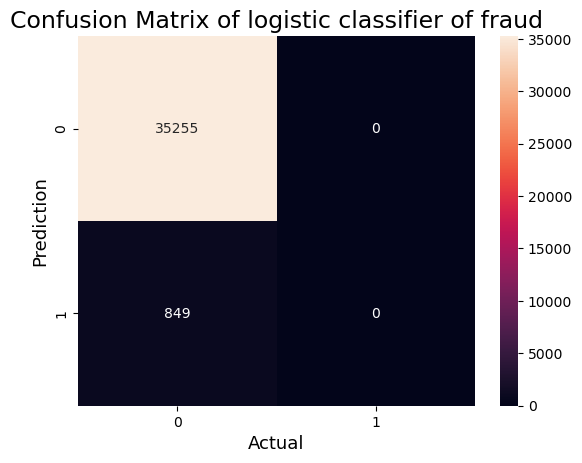

In [66]:
fraud_y_pred = lrf.predict(fraud_x_test)
 
# compute the confusion matrix
cm = confusion_matrix(fraud_y_test,fraud_y_pred)
 
#Plot the confusion matrix.
sns.heatmap(cm,annot=True,fmt='g')
plt.ylabel('Prediction',fontsize=13)
plt.xlabel('Actual',fontsize=13)
plt.title('Confusion Matrix of logistic classifier of fraud',fontsize=17)
plt.show()

In [67]:
lrl=LogisticRegression(max_iter=2000)
lrl.fit(late_x_train,late_y_train)

/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=2000)

In [68]:
lrl.score(late_x_test,late_y_test)

0.6464657655661422

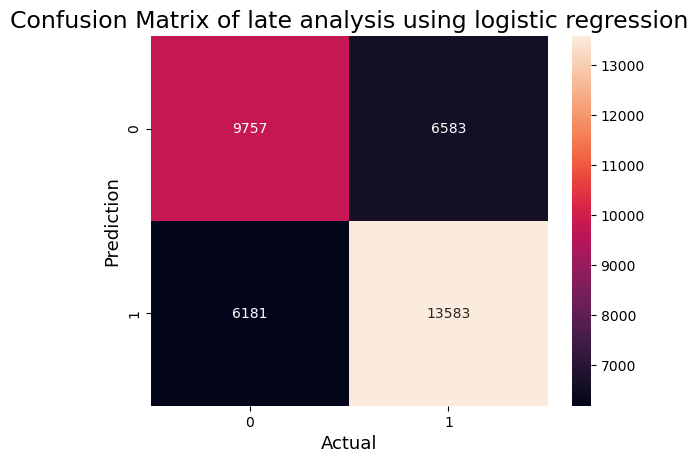

In [69]:
late_y_pred = lrl.predict(late_x_test)
 
# compute the confusion matrix
cm = confusion_matrix(late_y_test,late_y_pred)
 
#Plot the confusion matrix.
sns.heatmap(cm,annot=True,fmt='g')
plt.ylabel('Prediction',fontsize=13)
plt.xlabel('Actual',fontsize=13)
plt.title('Confusion Matrix of late analysis using logistic regression',fontsize=17)
plt.show()

In [70]:
dtrf=DecisionTreeClassifier()
dtrf.fit(fraud_x_train,fraud_y_train)

DecisionTreeClassifier()

In [71]:
dtrf.score(fraud_x_test,fraud_y_test)

0.9823011300686905

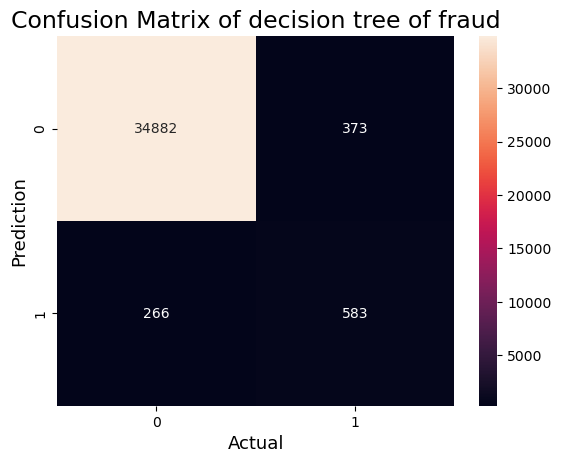

In [72]:
fraud_y_pred = dtrf.predict(fraud_x_test)
 
# compute the confusion matrix
cm = confusion_matrix(fraud_y_test,fraud_y_pred)
 
#Plot the confusion matrix.
sns.heatmap(cm,annot=True,fmt='g')
plt.ylabel('Prediction',fontsize=13)
plt.xlabel('Actual',fontsize=13)
plt.title('Confusion Matrix of decision tree of fraud',fontsize=17)
plt.show()

In [73]:
dtrl=DecisionTreeClassifier()
dtrl.fit(late_x_train,late_y_train)

DecisionTreeClassifier()

In [74]:
dtrl.score(late_x_test,late_y_test)

0.8510691336140039

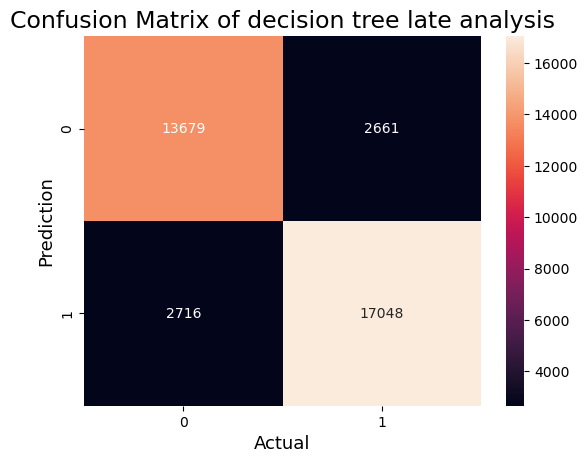

In [75]:
late_y_pred = dtrl.predict(late_x_test)
 
# compute the confusion matrix
cm = confusion_matrix(late_y_test,late_y_pred)
 
#Plot the confusion matrix.
sns.heatmap(cm,annot=True,fmt='g')
plt.ylabel('Prediction',fontsize=13)
plt.xlabel('Actual',fontsize=13)
plt.title('Confusion Matrix of decision tree late analysis',fontsize=17)
plt.show()

### random tree classification

In [76]:
classifierf= RandomForestClassifier(n_estimators= 50, criterion="entropy",)  
classifierf.fit(fraud_x_train,fraud_y_train)


RandomForestClassifier(criterion='entropy', n_estimators=50)

In [77]:
classifierl= RandomForestClassifier(n_estimators= 50, criterion="entropy",)  
classifierl.fit(late_x_train,late_y_train)

RandomForestClassifier(criterion='entropy', n_estimators=50)

In [78]:
classifierf.score(fraud_x_test,fraud_y_test)*100

97.75925105251495

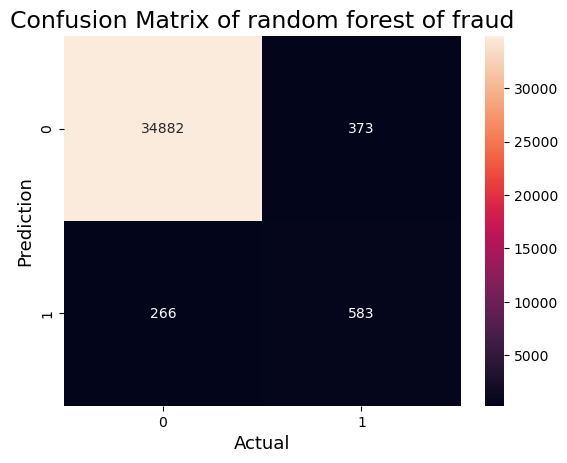

In [79]:
classifier_y_pred = classifierf.predict(fraud_x_test)
 
# compute the confusion matrix
cm = confusion_matrix(fraud_y_test,fraud_y_pred)
 
#Plot the confusion matrix.
sns.heatmap(cm,annot=True,fmt='g')
plt.ylabel('Prediction',fontsize=13)
plt.xlabel('Actual',fontsize=13)
plt.title('Confusion Matrix of random forest of fraud',fontsize=17)
plt.show()

In [80]:
classifierl.score(late_x_test,late_y_test)*100

77.39031686239753

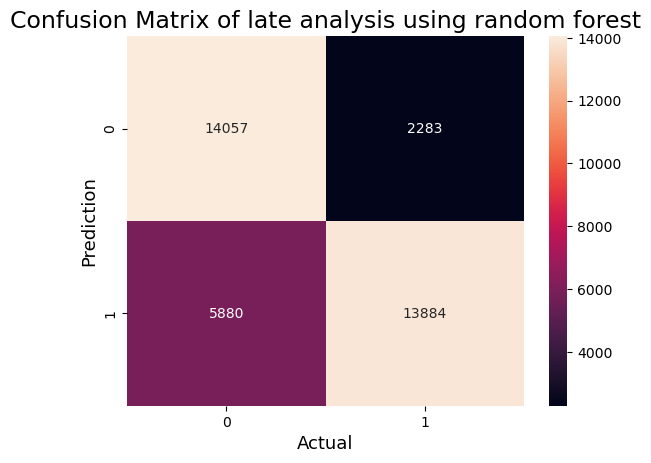

In [81]:
late_y_pred = classifierl.predict(late_x_test)
 
# compute the confusion matrix
cm = confusion_matrix(late_y_test,late_y_pred)
 
#Plot the confusion matrix.
sns.heatmap(cm,annot=True,fmt='g')
plt.ylabel('Prediction',fontsize=13)
plt.xlabel('Actual',fontsize=13)
plt.title('Confusion Matrix of late analysis using random forest',fontsize=17)
plt.show()

### KN NEIGHBOURS

In [82]:
k_classifierf= KNeighborsClassifier(n_neighbors=200, metric='minkowski', p=2 )  
k_classifierf.fit(fraud_x_train,fraud_y_train)

KNeighborsClassifier(n_neighbors=200)

In [83]:
k_classifierf.score(fraud_x_test,fraud_y_test)

0.9764846000443164

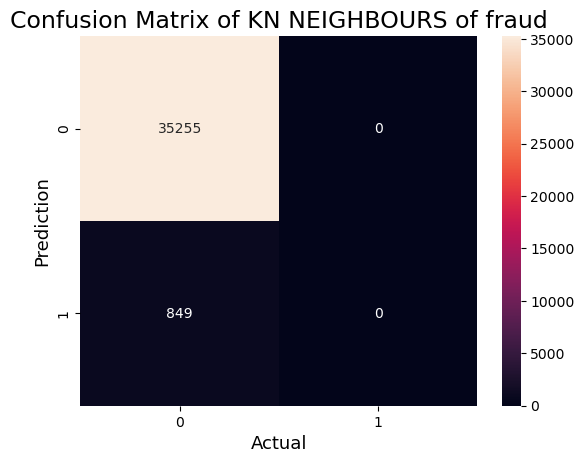

In [84]:
fraud_y_pred = k_classifierf.predict(fraud_x_test)
 
# compute the confusion matrix
cm = confusion_matrix(fraud_y_test,fraud_y_pred)
 
#Plot the confusion matrix.
sns.heatmap(cm,annot=True,fmt='g')
plt.ylabel('Prediction',fontsize=13)
plt.xlabel('Actual',fontsize=13)
plt.title('Confusion Matrix of KN NEIGHBOURS of fraud',fontsize=17)
plt.show()

In [85]:
k_classifierl= KNeighborsClassifier(n_neighbors=200, metric='minkowski', p=2 )  
k_classifierl.fit(late_x_train,late_y_train)

KNeighborsClassifier(n_neighbors=200)

In [86]:
k_classifierl.score(late_x_test,late_y_test)

0.5509084865942832

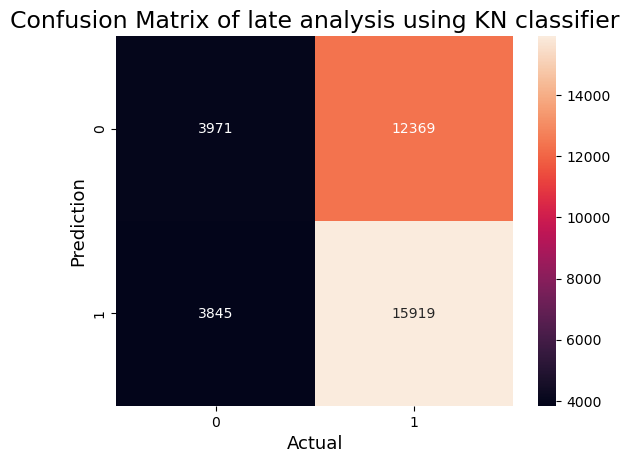

In [87]:
late_y_pred = k_classifierl.predict(late_x_test)
 
# compute the confusion matrix
cm = confusion_matrix(late_y_test,late_y_pred)
 
#Plot the confusion matrix.
sns.heatmap(cm,annot=True,fmt='g')
plt.ylabel('Prediction',fontsize=13)
plt.xlabel('Actual',fontsize=13)
plt.title('Confusion Matrix of late analysis using KN classifier',fontsize=17)
plt.show()

### GAUSSIAN 

In [88]:
modelf=GaussianNB()
modelf.fit(fraud_x_train,fraud_y_train)

GaussianNB()

In [89]:
modell=GaussianNB()
modell.fit(late_x_train,late_y_train)

GaussianNB()

In [90]:
modelf.score(fraud_x_test,fraud_y_test)

0.974434965654775

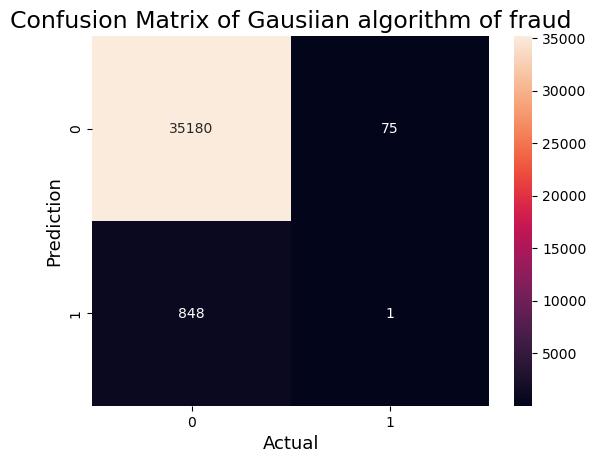

In [91]:
fraud_y_pred =modelf.predict(fraud_x_test)
 
# compute the confusion matrix
cm = confusion_matrix(fraud_y_test,fraud_y_pred)
 
#Plot the confusion matrix.
sns.heatmap(cm,annot=True,fmt='g')
plt.ylabel('Prediction',fontsize=13)
plt.xlabel('Actual',fontsize=13)
plt.title('Confusion Matrix of Gausiian algorithm of fraud',fontsize=17)
plt.show()

In [92]:
modell.score(late_x_test,late_y_test)

0.6903944161311766

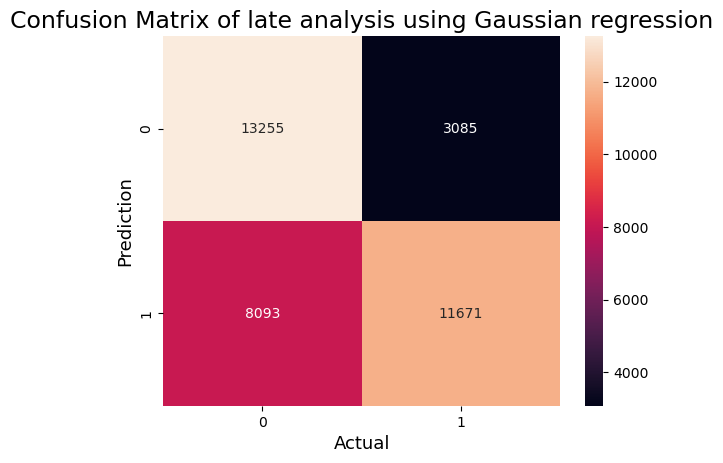

In [93]:
late_y_pred = modell.predict(late_x_test)
 
# compute the confusion matrix
cm = confusion_matrix(late_y_test,late_y_pred)
 
#Plot the confusion matrix.
sns.heatmap(cm,annot=True,fmt='g')
plt.ylabel('Prediction',fontsize=13)
plt.xlabel('Actual',fontsize=13)
plt.title('Confusion Matrix of late analysis using Gaussian regression',fontsize=17)
plt.show()

### EXTRA TREE CLASSIFIER

In [94]:
from sklearn.ensemble import ExtraTreesClassifier
extra_tree_forestf = ExtraTreesClassifier(n_estimators = 5,
                                        criterion ='entropy', max_features = 2)
extra_tree_forestf.fit(fraud_x_train,fraud_y_train)

ExtraTreesClassifier(criterion='entropy', max_features=2, n_estimators=5)

In [95]:
from sklearn.ensemble import ExtraTreesClassifier
extra_tree_forestl = ExtraTreesClassifier(n_estimators = 5,
                                        criterion ='entropy', max_features = 2)
extra_tree_forestl.fit(late_x_train,late_y_train)

ExtraTreesClassifier(criterion='entropy', max_features=2, n_estimators=5)

In [96]:
extra_tree_forestf.score(fraud_x_test,fraud_y_test)

0.9773432306669622

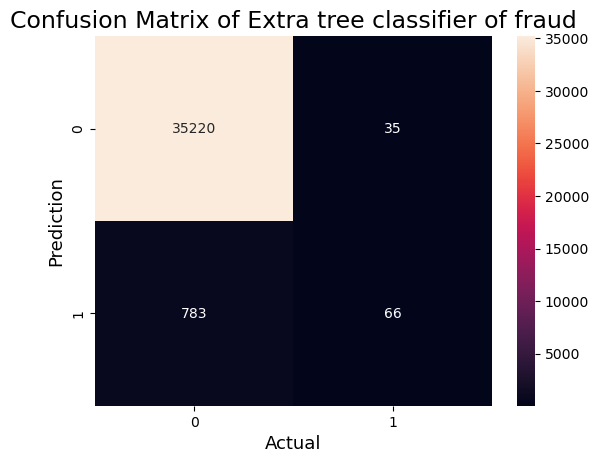

In [97]:
fraud_y_pred = extra_tree_forestf.predict(fraud_x_test)
 
# compute the confusion matrix
cm = confusion_matrix(fraud_y_test,fraud_y_pred)
 
#Plot the confusion matrix.
sns.heatmap(cm,annot=True,fmt='g')
plt.ylabel('Prediction',fontsize=13)
plt.xlabel('Actual',fontsize=13)
plt.title('Confusion Matrix of Extra tree classifier of fraud',fontsize=17)
plt.show()

In [98]:
extra_tree_forestl.score(late_x_test,late_y_test)

0.6836084644360736

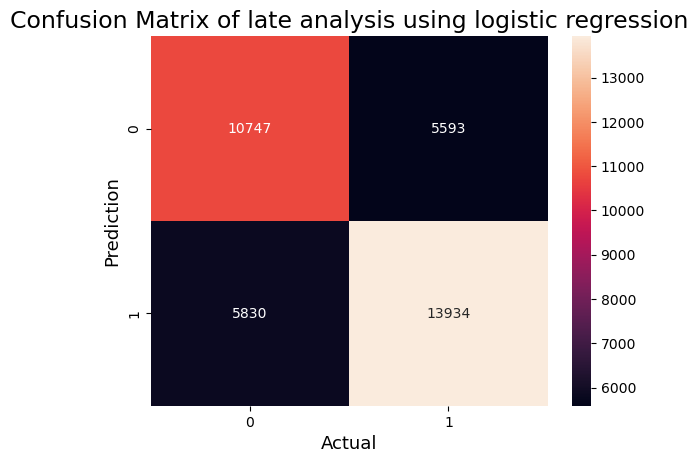

In [99]:
late_y_pred = extra_tree_forestl.predict(late_x_test)
 
# compute the confusion matrix
cm = confusion_matrix(late_y_test,late_y_pred)
 
#Plot the confusion matrix.
sns.heatmap(cm,annot=True,fmt='g')
plt.ylabel('Prediction',fontsize=13)
plt.xlabel('Actual',fontsize=13)
plt.title('Confusion Matrix of late analysis using logistic regression',fontsize=17)
plt.show()